In [1]:
%pip install transformers torch pandas scikit-learn matplotlib

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 6.8 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 855.2/855.2 kB 6.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 6.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 6.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 6.8 MB/s  0:01:18m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 6.7 MB/s  0:01:22m0:00:0100:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 7.2 MB/s  0:00:23m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 7.1 MB/s  0:00:30m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 7.1 MB/s  0:00:08m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 7.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from transformers import pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

clasificador = pipeline(
    task="sentiment-analysis",
    model="pysentimiento/robertuito-sentiment-analysis",
    device=-1  # Utilizar CPU.
)

/var/data/python/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 7809.10it/s]


In [2]:
df = pd.DataFrame({
    "texto": [
        "Me encanta esta aplicación.",
        "Funciona perfectamente, la recomiendo.",
        "El soporte me ha ayudado muchísimo.",
        "La aplicación falla continuamente.",
        "No me gusta nada esta actualización.",
        "He perdido mis archivos, qué decepción.",
        "La aplicación tiene tres idiomas.",
        "La versión instalada es la 2.0.",
        "El archivo se guarda en formato CSV."
    ],
    "referencia": [
        "POS", "POS", "POS",
        "NEG", "NEG", "NEG",
        "NEU", "NEU", "NEU"
    ]
})

In [3]:
predicciones = clasificador(
    df["texto"].tolist(),
    truncation=True,
    max_length=128
)

df["prediccion"] = [p["label"] for p in predicciones]
df["puntuacion"] = [p["score"] for p in predicciones]
df["acierto"] = df["referencia"] == df["prediccion"]

display(df)

,texto,referencia,prediccion,puntuacion,acierto
0,Me encanta esta aplicación.,POS,POS,0.955938,True
1,"Funciona perfectamente, la recomiendo.",POS,POS,0.964836,True
2,El soporte me ha ayudado muchísimo.,POS,POS,0.966450,True
3,La aplicación falla continuamente.,NEG,NEG,0.908332,True
4,No me gusta nada esta actualización.,NEG,NEG,0.957036,True
5,"He perdido mis archivos, qué decepción.",NEG,NEG,0.977319,True
6,La aplicación tiene tres idiomas.,NEU,NEU,0.855119,True
7,La versión instalada es la 2.0.,NEU,NEU,0.783773,True
8,El archivo se guarda en formato CSV.,NEU,NEU,0.903061,True


              precision    recall  f1-score   support

         NEG      1.000     1.000     1.000         3
         NEU      1.000     1.000     1.000         3
         POS      1.000     1.000     1.000         3

    accuracy                          1.000         9
   macro avg      1.000     1.000     1.000         9
weighted avg      1.000     1.000     1.000         9



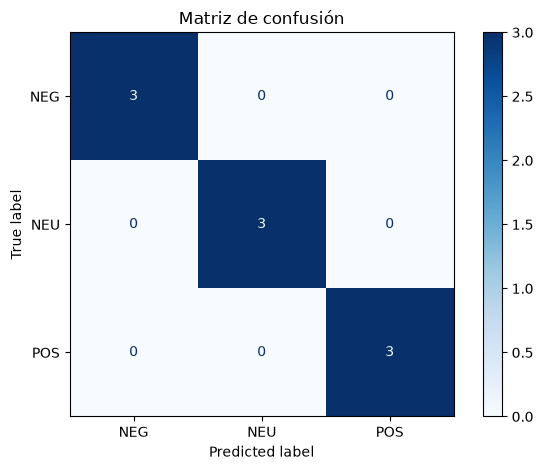

In [4]:
etiquetas = ["NEG", "NEU", "POS"]

print(classification_report(
    df["referencia"],
    df["prediccion"],
    labels=etiquetas,
    digits=3,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    df["referencia"],
    df["prediccion"],
    labels=etiquetas,
    cmap="Blues"
)

plt.title("Matriz de confusión")
plt.tight_layout()
plt.show()

In [8]:
display(df.loc[~df["acierto"]]) #Solo muestra registros con acierto False

,texto,referencia,prediccion,puntuacion,acierto
